<!--
Projeto : Agente Especialista em GRC - RAG + LLM local sobre o COSO ERM 2017
Arquivo : llama/experimentos_N2.ipynb
-->
# Experimentos da N2 &ndash; Avaliação do Agente Especialista em GRC

**Universidade Presbiteriana Mackenzie** &ndash; Faculdade de Computação e Informática
Sistemas de Informação &ndash; Inteligência Artificial (7ºK, noite) &ndash; Prof. Dr. Leandro Zerbinatti

| Integrante | RA | E-mail |
|---|---|---|
| Guilherme Martins Silva | 10417140 | 10417140@mackenzista.com.br |
| Enzo Ribeiro | 10418262 | 10418262@mackenzista.com.br |
| Pedro Nogueira Ribeiro | 10324924 | 10324924@mackenzista.com.br |

**Síntese:** executa os experimentos prometidos na seção 6 do relatório N1 e gera os números e
figuras da seção de Resultados do relatório N2 (salvos em `llama/resultados/`):

1. **Recuperação &ndash; comparação com baselines:** aleatório, BM25 (lexical), denso puro, MMR, denso + re-ranking e o pipeline do agente (MMR + re-ranking), com Hit Rate, MRR e Precision@1.
2. **Tamanho de chunk e limpeza do corpus:** 200 / 400 / 800 tokens e corpus bruto &times; corpus limpo (heurística do ligature "fi" da EDA).
3. **Avaliação fim a fim das respostas do LLM:** 31 perguntas (5 componentes, 20 princípios, princípios por componente e 5 perguntas fora do escopo) e relação entre perplexidade e qualidade da resposta.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-11-15 | Enzo Ribeiro | Versão inicial com os três experimentos da N2. |

In [1]:
import gc
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch

sys.path.insert(0, os.path.abspath(".."))   # raiz do repositório -> pacote "llama"

from langchain_chroma import Chroma

from llama.RAG.BuildVectorStore import PDFVectorStore
from llama.RAG.rank_context import RankContext
from llama.RAG.text_cleaning import clean_text
from llama.EvaluationRAG import RAGEvaluator
from llama.eval_dataset import RAW_DATASET, load_dataset
from llama.answer_dataset import build_answer_dataset, score_answer, PRINCIPLES
from llama import baselines as B

%matplotlib inline
pd.set_option("display.max_colwidth", 120)

RESULTS = os.path.abspath("resultados")
os.makedirs(RESULTS, exist_ok=True)

# Modelo gerador: o repositório oficial meta-llama exige aceite da licença no HuggingFace.
# "unsloth/Llama-3.2-3B-Instruct" é um espelho público com os MESMOS pesos.
MODEL_ID = os.environ.get("LLAMA_MODEL_ID", "meta-llama/Llama-3.2-3B-Instruct")
THRESHOLD = 0.77          # ponto de operação escolhido na avaliação original do retriever
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Modelo gerador:", MODEL_ID)

/home/enzoribeiroz/VSCode/mackenzie/ai/ai_lab_mack/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Modelo gerador: unsloth/Llama-3.2-3B-Instruct


## 1. Carga do índice, do re-ranker e do conjunto de avaliação

In [2]:
vs = PDFVectorStore()                 # BAAI/bge-m3, índice persistido em llama/RAG/db
chroma = vs._load_db()
chunks = B.load_chunks(chroma)
reranker = RankContext("BAAI/bge-reranker-v2-m3", top_n=6, verbose=False)

dataset = load_dataset("pt")
query_en = {s["query"]: s["query_en"] for s in RAW_DATASET}
# o avaliador só codifica ~7 textos por pergunta: na CPU ele não disputa VRAM com o índice e o re-ranker
evaluator = RAGEvaluator(pipeline_fn=None, dataset=dataset, model_name="BAAI/bge-m3", device="cpu")

print(f"Chunks indexados: {len(chunks)} | perguntas de avaliação: {len(dataset)}")

INFO:RAG:🚀 Carregando embeddings...


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-m3: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-m3'.


INFO:sentence_transformers.base.model:Loading SentenceTransformer model from BAAI/bge-m3.


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 51871.61it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 9/393 [00:00<00:38,  9.98it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 424.10it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 47726.35it/s]

Chunks indexados: 293 | perguntas de avaliação: 16


## 2. Recuperação: pipeline do agente &times; baselines

Todos os recuperadores devolvem **6 trechos** (o que entra no prompt) a partir dos mesmos 293 chunks.
Um trecho conta como acerto quando a similaridade de cosseno (bge-m3) com o trecho de referência é
&ge; ao threshold. O recuperador **aleatório** mostra o "piso" da métrica: quanto dela se obtém por acaso.

In [3]:
retrievers = {
    "Aleatório": B.random_retriever(chunks),
    "BM25 (pergunta PT)": B.bm25_retriever(chunks),
    "BM25 (pergunta EN)": B.bm25_retriever(chunks, query_map=query_en),
    "Denso (bge-m3)": B.dense_retriever(chroma),
    "MMR": B.mmr_retriever(chroma),
    "Denso + re-ranking": B.dense_rerank_retriever(chroma, reranker),
    "MMR + re-ranking (agente)": B.mmr_rerank_retriever(chroma, reranker),
}

curves, per_query = {}, {}
for name, fn in retrievers.items():
    t0 = time.time()
    evaluator.pipeline_fn = fn
    evaluator._cache = {}
    curves[name] = evaluator.evaluate(k=20, similarity_threshold=0.70, verbose=False)
    per_query[name] = evaluator.per_query(k=20, similarity_threshold=THRESHOLD)
    print(f"{name:<28} ok ({time.time() - t0:.1f}s)")

def at(df, thr):
    return df.loc[(df.similarity_threshold - thr).abs() < 1e-9].iloc[0]

rows = []
for name, df in curves.items():
    for thr in (THRESHOLD, 0.85):
        r = at(df, thr)
        rows.append({"recuperador": name, "threshold": thr, "hit_rate": r.hit_rate,
                     "mrr": r.mrr, "precision_at_1": r.precision_at_1})
retrieval = pd.DataFrame(rows)
retrieval.to_csv(f"{RESULTS}/recuperacao_comparacao.csv", index=False)
pd.concat(curves, names=["recuperador"]).to_csv(f"{RESULTS}/recuperacao_curvas.csv")
retrieval.pivot(index="recuperador", columns="threshold").round(3).reindex(list(retrievers))

Aleatório                    ok (88.0s)


BM25 (pergunta PT)           ok (89.0s)


BM25 (pergunta EN)           ok (87.0s)


Denso (bge-m3)               ok (87.2s)


MMR                          ok (88.6s)


Denso + re-ranking           ok (91.9s)


MMR + re-ranking (agente)    ok (92.3s)


hit_rate           mrr        precision_at_1       
threshold                     0.77   0.85   0.77   0.85           0.77   0.85
recuperador                                                                  
Aleatório                    0.375  0.125  0.158  0.023          0.062  0.000
BM25 (pergunta PT)           0.188  0.125  0.135  0.042          0.125  0.000
BM25 (pergunta EN)           0.812  0.312  0.583  0.198          0.438  0.125
Denso (bge-m3)               0.812  0.250  0.630  0.177          0.500  0.125
MMR                          0.625  0.250  0.547  0.172          0.500  0.125
Denso + re-ranking           0.938  0.562  0.729  0.304          0.625  0.188
MMR + re-ranking (agente)    0.812  0.500  0.630  0.323          0.500  0.188

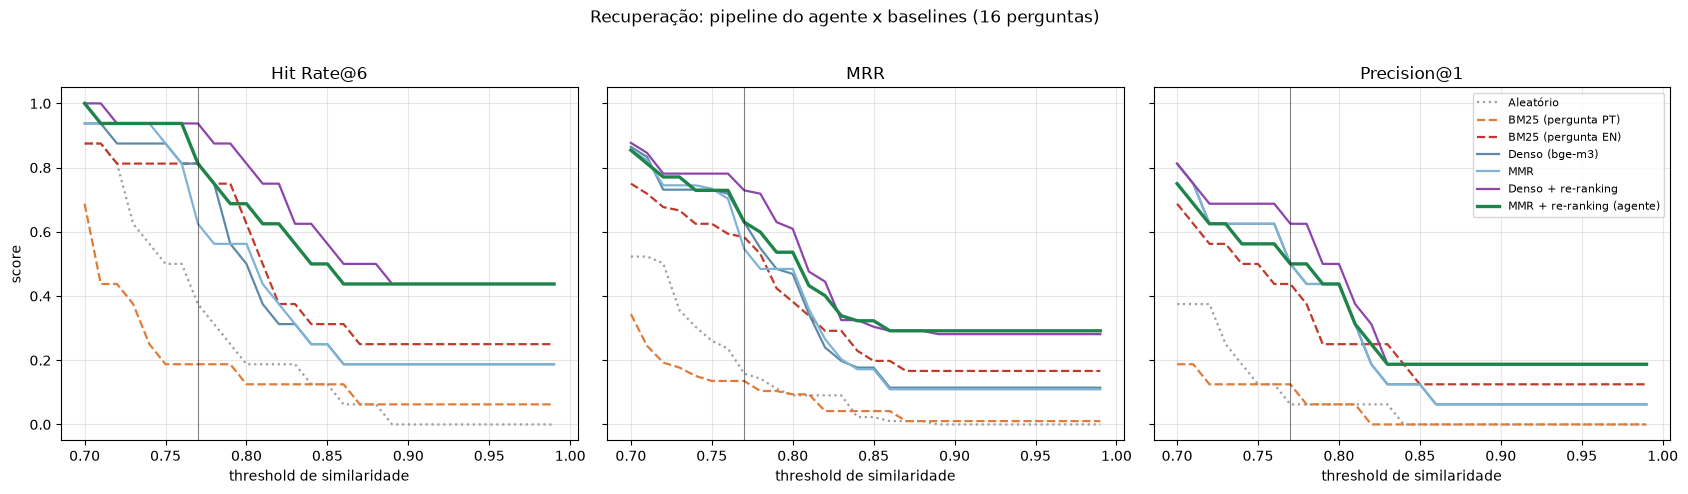

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
styles = {"Aleatório": ("#9e9e9e", ":"), "BM25 (pergunta PT)": ("#e07b39", "--"),
          "BM25 (pergunta EN)": ("#c0392b", "--"), "Denso (bge-m3)": ("#5d8aa8", "-"),
          "MMR": ("#7fb3d5", "-"), "Denso + re-ranking": ("#8e44ad", "-"),
          "MMR + re-ranking (agente)": ("#1e8449", "-")}
for ax, (col, title) in zip(axs, [("hit_rate", "Hit Rate@6"), ("mrr", "MRR"), ("precision_at_1", "Precision@1")]):
    for name, df in curves.items():
        color, ls = styles[name]
        ax.plot(df.similarity_threshold, df[col], ls, color=color, lw=2.4 if "agente" in name else 1.6, label=name)
    ax.axvline(THRESHOLD, color="black", lw=0.8, alpha=0.5)
    ax.set_title(title); ax.set_xlabel("threshold de similaridade"); ax.grid(alpha=0.3)
axs[0].set_ylabel("score"); axs[2].legend(fontsize=8, loc="upper right")
plt.suptitle("Recuperação: pipeline do agente x baselines (16 perguntas)", y=1.02)
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_recuperacao_baselines.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
# Detalhe por pergunta no threshold de operação: posição do 1º acerto em cada recuperador
detail = pd.DataFrame({name: pq.first_hit_rank for name, pq in per_query.items()})
detail.insert(0, "pergunta", per_query["Aleatório"]["query"])
detail.to_csv(f"{RESULTS}/recuperacao_por_pergunta.csv", index=False)
detail

,pergunta,Aleatório,BM25 (pergunta PT),BM25 (pergunta EN),Denso (bge-m3),MMR,Denso + re-ranking,MMR + re-ranking (agente)
0,Qual é a definição de Enterprise Risk Management?,2.0,1.0,1.0,1.0,1.0,1.0,1.0
1,Quantos e quais sãos componentes que estruturam o framework (ERM)?,5.0,NaN,6.0,4.0,NaN,3.0,NaN
2,O ERM deve ser integrado à estratégia?,NaN,NaN,1.0,3.0,NaN,3.0,4.0
3,O ERM é um departamento separado?,NaN,NaN,2.0,1.0,1.0,1.0,2.0
4,Qual a importancia da supervisão em cima do Enterprise Risk Management?,4.0,NaN,NaN,NaN,NaN,6.0,2.0
5,Qual é o objetivo do ERM em relação ao valor?,4.0,NaN,1.0,2.0,NaN,1.0,1.0
6,O ERM reduz surpresas organizacionais?,NaN,6.0,1.0,1.0,1.0,1.0,1.0
7,A cultura faz parte do ERM?,1.0,NaN,2.0,1.0,1.0,2.0,2.0
8,Como o ERM contribui para o alinhamento entre performance e risco?,NaN,NaN,3.0,2.0,NaN,1.0,NaN
9,Qual é a relação entre ERM e resiliência organizacional?,NaN,NaN,1.0,1.0,1.0,1.0,1.0


## 3. Tamanho do chunk e limpeza do corpus

O índice persistido usa chunks de 400 tokens (overlap 80) construídos sobre o texto **bruto**. Aqui os
índices alternativos são reconstruídos em memória (sem alterar `llama/RAG/db`) e avaliados com o
pipeline completo do agente (MMR + re-ranking). O corpus "limpo" aplica a mesma heurística da EDA da N1
(remoção dos marcadores `break` e correção do ligature "fi").

In [6]:
configs = [
    ("bruto-200", 200, 40, None),
    ("bruto-400 (atual)", 400, 80, None),
    ("bruto-800", 800, 160, None),
    ("limpo-400", 400, 80, clean_text),
]
chunk_rows, chunk_curves = [], {}
for name, size, overlap, cleaner in configs:
    vs.chunk_size, vs.chunk_overlap, vs.text_cleaner = size, overlap, cleaner
    exp_chunks = vs.build_chunks()
    store = Chroma.from_documents(exp_chunks, embedding=vs.embeddings,
                                  collection_name="exp_" + str(abs(hash(name))))
    evaluator.pipeline_fn = B.mmr_rerank_retriever(store, reranker)
    evaluator._cache = {}
    df = evaluator.evaluate(k=20, similarity_threshold=0.70, verbose=False)
    chunk_curves[name] = df
    r77, r85 = at(df, THRESHOLD), at(df, 0.85)
    chunk_rows.append({"configuração": name, "chunks": len(exp_chunks),
                       "hit_rate@0.77": r77.hit_rate, "mrr@0.77": r77.mrr, "p@1@0.77": r77.precision_at_1,
                       "hit_rate@0.85": r85.hit_rate, "mrr@0.85": r85.mrr})
    store.delete_collection()
    print(f"{name:<18} chunks={len(exp_chunks)}")

# restaura a configuração padrão
vs.chunk_size, vs.chunk_overlap, vs.text_cleaner = 400, 80, None
chunk_table = pd.DataFrame(chunk_rows)
chunk_table.to_csv(f"{RESULTS}/chunk_e_limpeza.csv", index=False)
chunk_table.round(3)

INFO:RAG:📄 documentos carregados: 1


INFO:RAG:🧱 seções detectadas: 96


INFO:RAG:✂️ chunks gerados: 582


INFO:RAG:🧹 hash removidos: 1


INFO:RAG:🧹 semantic removidos: 10


INFO:RAG:📄 documentos carregados: 1


... (15 outputs left out)

INFO:RAG:🧹 hash removidos: 0


INFO:RAG:🧹 semantic removidos: 7


limpo-400          chunks=295


,configuração,chunks,hit_rate@0.77,mrr@0.77,p@1@0.77,hit_rate@0.85,mrr@0.85
0,bruto-200,571,0.750,0.672,0.625,0.312,0.229
1,bruto-400 (atual),293,0.812,0.630,0.500,0.500,0.323
2,bruto-800,165,0.875,0.474,0.312,0.375,0.193
3,limpo-400,295,0.812,0.549,0.375,0.438,0.255


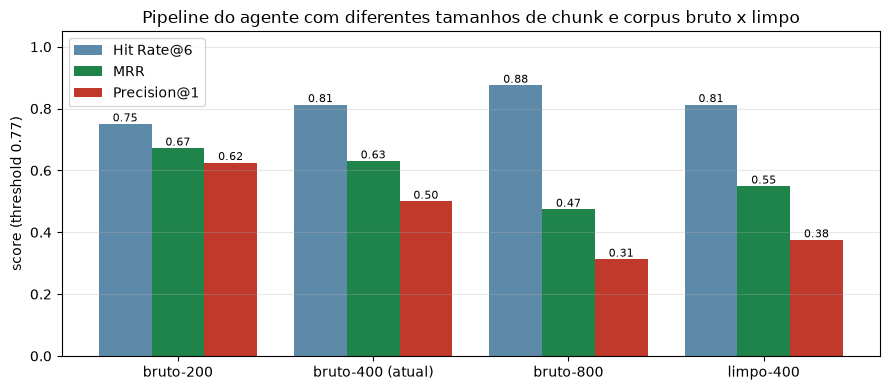

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(chunk_table))
w = 0.27
for i, (col, label, color) in enumerate([("hit_rate@0.77", "Hit Rate@6", "#5d8aa8"),
                                         ("mrr@0.77", "MRR", "#1e8449"),
                                         ("p@1@0.77", "Precision@1", "#c0392b")]):
    bars = ax.bar([p + (i - 1) * w for p in x], chunk_table[col], w, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(chunk_table["configuração"])
ax.set_ylim(0, 1.05); ax.set_ylabel(f"score (threshold {THRESHOLD})"); ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.set_title("Pipeline do agente com diferentes tamanhos de chunk e corpus bruto x limpo")
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_chunk_limpeza.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Avaliação fim a fim das respostas

Os trechos de contexto são recuperados primeiro (GPU), depois os modelos de recuperação são liberados
e o Llama 3.2 3B (4 bits) é carregado sozinho na GPU. A memória conversacional fica **desligada** para
que uma resposta não contamine a seguinte. A nota de cada resposta é a fração dos conceitos esperados
(em PT ou EN) presentes no texto; para as perguntas fora do escopo, a nota é 1 se o agente se abstém.

In [8]:
import re

items = build_answer_dataset()
contexts = {}
for it in items:
    contexts[it["id"]] = B.mmr_rerank_docs(chroma, reranker, it["question"])

def context_has_principle(docs, n):
    pat = re.compile(rf"principle\s+{n}\b", re.I)
    return any(pat.search(d.page_content) for d in docs)

print(f"{len(items)} perguntas; contextos recuperados.")

# libera a GPU para o LLM
# (fn e store, variáveis dos laços acima, ainda referenciam o embedder e o re-ranker)
for _name in ("evaluator", "reranker", "retrievers", "vs", "chroma", "fn", "store"):
    globals().pop(_name, None)
get_ipython().run_line_magic("reset", "-f out")   # o cache de saídas do IPython também guarda referências
gc.collect(); torch.cuda.empty_cache()
print(f"VRAM ocupada antes do LLM: {torch.cuda.memory_allocated() / 2**30:.2f} GB")

31 perguntas; contextos recuperados.


Flushing output cache (3 entries)


VRAM ocupada antes do LLM: 0.01 GB


In [9]:
from llama.call_llama import CallLlama

llm = CallLlama(model_id=MODEL_ID, use_memory=False, aux_device="cpu", verbose=False,
                log_file="logs_llama/experimentos_n2.jsonl")

🚀 Inicializando call_llama...


Progresso Geral:   0%|          | 0/5

🔍 Carregando sistema de Re Rank:   0%|          | 0/5

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 10375.67it/s]


🔍 Carregando sistema de Re Rank:  20%|██        | 1/5

... (44 outputs left out)


⚙️ Carregando modelo Llama local:  80%|████████  | 4/5

📊 Inicializando Answer Evaluation:  80%|████████  | 4/5

📊 Inicializando Answer Evaluation: 100%|██████████| 5/5


✅ call_llama inicializado com sucesso!


In [10]:
answers = []
for it in items:
    t0 = time.time()
    ans = llm.invoke(it["question"], rag_docs=contexts[it["id"]], seed=42)
    m = llm.last_metrics
    n = int(it["id"][1:]) if it["category"] == "principio" else None
    answers.append({
        "id": it["id"], "categoria": it["category"], "pergunta": it["question"],
        "referencia": it.get("reference", ""), "resposta": ans,
        "nota": score_answer(ans, it["expected"]),
        "perplexidade": m["perplexity"], "logprob_medio": m["mean_logprob"],
        "tokens_gerados": m["n_tokens"], "segundos": round(time.time() - t0, 1),
        "contexto_tem_principio": context_has_principle(contexts[it["id"]], n) if n else None,
        "fontes": m["sources"],
    })
res = pd.DataFrame(answers)
res.to_csv(f"{RESULTS}/respostas_llm.csv", index=False)
with open(f"{RESULTS}/respostas_llm.json", "w", encoding="utf-8") as f:
    json.dump(answers, f, ensure_ascii=False, indent=2)
res[["id", "categoria", "nota", "perplexidade", "tokens_gerados", "segundos", "contexto_tem_principio"]]

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Mean logprob: -0.1556
Perplexity: 1.1684


[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Mean logprob: -0.1957
Perplexity: 1.2161


... (54 outputs left out)

[transformers] Both `max_new_tokens` (=512) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Mean logprob: -0.0768
Perplexity: 1.0798



Mean logprob: -0.1322
Perplexity: 1.1413


,id,categoria,nota,perplexidade,tokens_gerados,segundos,contexto_tem_principio
0,C0,componentes,0.400000,1.168387,512,12.0,None
1,P1,principio,0.500000,1.216126,289,7.0,False
2,P2,principio,0.500000,1.206365,321,7.9,False
3,P3,principio,1.000000,1.259001,40,1.7,True
4,P4,principio,1.000000,1.253396,203,5.2,True
5,P5,principio,0.250000,1.290513,210,5.5,True
6,P6,principio,0.000000,1.284091,62,2.1,False
7,P7,principio,1.000000,1.249336,203,5.1,True
8,P8,principio,0.250000,1.260137,254,6.3,False
9,P9,principio,1.000000,1.309132,87,2.8,False


In [11]:
summary = res.groupby("categoria", sort=False).agg(
    perguntas=("id", "count"), nota_media=("nota", "mean"),
    respostas_completas=("nota", lambda s: (s == 1).sum()),
    perplexidade_media=("perplexidade", "mean"), tempo_medio_s=("segundos", "mean")).round(3)
summary.to_csv(f"{RESULTS}/respostas_resumo.csv")

princ = res[res.categoria == "principio"]
print("Princípios com o trecho 'Principle N' no contexto:", int(princ.contexto_tem_principio.sum()), "/ 20")
print("Nota média quando o trecho ESTÁ no contexto:    ", round(princ[princ.contexto_tem_principio == True].nota.mean(), 3))
print("Nota média quando o trecho NÃO está no contexto:", round(princ[princ.contexto_tem_principio == False].nota.mean(), 3))
in_scope = res[res.categoria != "fora_do_escopo"]
rho = in_scope[["perplexidade", "nota"]].corr(method="spearman").iloc[0, 1]
print(f"Correlação de Spearman (perplexidade x nota, perguntas no escopo): {rho:.3f}")
summary

Princípios com o trecho 'Principle N' no contexto: 10 / 20
Nota média quando o trecho ESTÁ no contexto:     0.618
Nota média quando o trecho NÃO está no contexto: 0.5
Correlação de Spearman (perplexidade x nota, perguntas no escopo): -0.014


,perguntas,nota_media,respostas_completas,perplexidade_media,tempo_medio_s
categoria,,,,,
componentes,1,0.400,0,1.168,12.00
principio,20,0.559,6,1.267,4.46
principios_do_componente,5,0.513,1,1.203,3.78
fora_do_escopo,5,0.000,0,1.178,7.70


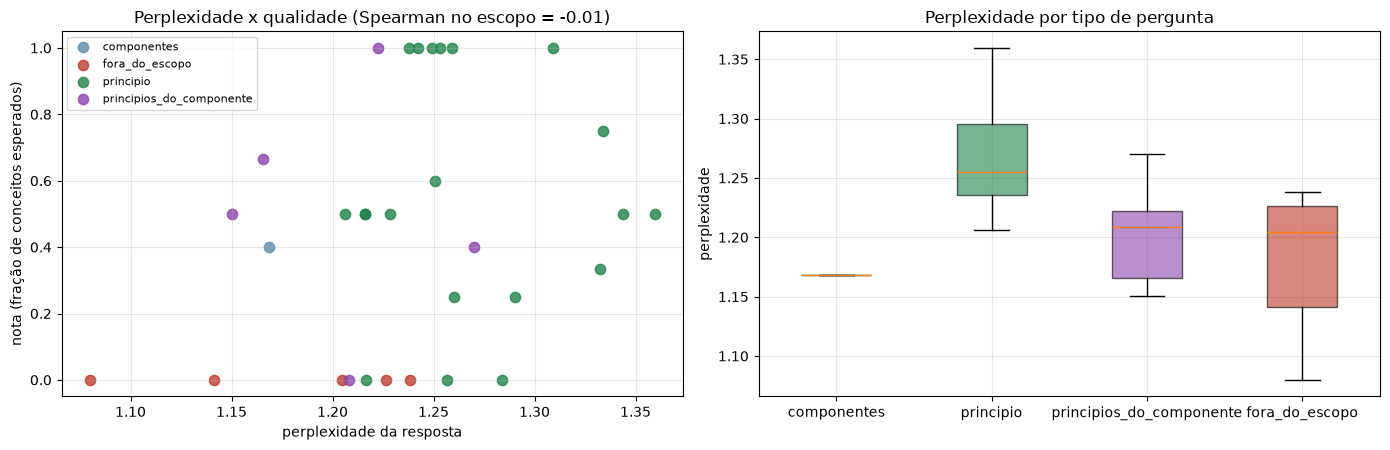

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
colors = {"componentes": "#5d8aa8", "principio": "#1e8449", "principios_do_componente": "#8e44ad", "fora_do_escopo": "#c0392b"}
for cat, g in res.groupby("categoria"):
    axs[0].scatter(g.perplexidade, g.nota, s=55, alpha=0.8, color=colors[cat], label=cat)
axs[0].set_xlabel("perplexidade da resposta"); axs[0].set_ylabel("nota (fração de conceitos esperados)")
axs[0].set_title(f"Perplexidade x qualidade (Spearman no escopo = {rho:.2f})"); axs[0].grid(alpha=0.3); axs[0].legend(fontsize=8)

order = list(colors)
data = [res[res.categoria == c].perplexidade for c in order]
bp = axs[1].boxplot(data, patch_artist=True)
axs[1].set_xticks(range(1, len(order) + 1), order)
for patch, c in zip(bp["boxes"], order):
    patch.set_facecolor(colors[c]); patch.set_alpha(0.6)
axs[1].set_ylabel("perplexidade"); axs[1].set_title("Perplexidade por tipo de pergunta"); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_perplexidade.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
# Exemplos de respostas (uma de cada categoria)
for cat in ["componentes", "principio", "principios_do_componente", "fora_do_escopo"]:
    r = res[res.categoria == cat].iloc[0]
    print(f"### [{r.id}] {r.pergunta}\n(nota={r.nota:.2f}, perplexidade={r.perplexidade:.2f})\n{r.resposta}\n")

### [C0] Quais são os cinco componentes do framework COSO ERM 2017?
(nota=0.40, perplexidade=1.17)
Os cinco componentes do Framework COSO ERM 2017 são:

1. **Governança e Cultura**: Este componente aborda a importância da governança e da cultura organizacional na gestão de riscos. Ele enfatiza a necessidade de uma cultura de risco que incentive a identificação e gestão de riscos, e a importância da governança na definição de políticas e procedimentos de gestão de riscos.

2. **Integração com Estratégia e Objetivos**: Este componente aborda a importância de integrar a gestão de riscos com a estratégia e os objetivos da organização. Ele enfatiza a necessidade de considerar os riscos ao estabelecer objetivos e estratégias, e de desenvolver um plano de gestão de riscos que atenda às necessidades da organização.

3. **Componentes e Princípios**: Este componente apresenta os cinco componentes do Framework COSO ERM 2017, que são:
	* **Governança e Cultura**: (acima)
	* **Integração com Estrat